# Phase 2 — BiLSTM generalization audit
Frozen-model diagnosis only. Reuse saved BiLSTM predictions/history; do not load model weights, retrain, or run Optuna. Load the primary dataset once. Fit training-mean, training-median and Ridge baselines using training data only. Select Ridge alpha by validation MAE from a fixed grid before its test evaluation. Test findings are diagnostic and must not drive tuning.

Feature names, event IDs and time provenance are unavailable. Distribution comparisons are descriptive; unknown dependence between sequences makes ordinary significance tests unreliable. No claims of leakage-free evaluation, chronological validity or forecasting.

Existing training curves, prediction/error figure and magnitude-range plot are reused. Only the magnitude-distribution figure is new.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, time
ROOT = Path.cwd().resolve()
if (ROOT / "bilstm" / "bilstm_dataset").is_dir():
    ROOT = ROOT / "bilstm"
assert (ROOT / "bilstm_dataset").is_dir()
if (ROOT / ".notebook-runtime").exists():
    sys.path.insert(0, str(ROOT / ".notebook-runtime"))
import numpy as np
import pandas as pd
import torch
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from scipy.stats import ks_2samp, wasserstein_distance
from threadpoolctl import threadpool_limits
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
RES = ROOT / "phase2_bilstm_results"
OUT = RES / "generalization_audit"
OUT.mkdir(exist_ok=True)
def digest(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()
def write_json(path, obj):
    temp = Path(path).with_suffix(".tmp")
    temp.write_text(json.dumps(obj, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)
protected = [ROOT / "bilstm_dataset/bilstm_dataset_seq20.pt", ROOT / "phase2_bilstm.ipynb"]
protected += [RES / name for name in (
    "best_bilstm.pt", "optuna_study.db", "test_predictions.npz", "test_predictions.csv",
    "test_metrics.json", "training_history.csv", "best_hyperparameters.json",
    "target_transform.json", "final_report.md", "training_validation_curves.png",
    "prediction_error_plots.png", "performance_by_magnitude.png")]
before = {p.relative_to(ROOT).as_posix(): digest(p) for p in protected}
history = pd.read_csv(RES / "training_history.csv")
original_metrics = json.loads((RES / "test_metrics.json").read_text())
transform = json.loads((RES / "target_transform.json").read_text())
with np.load(RES / "test_predictions.npz", allow_pickle=False) as cache:
    actual = cache["actual"].astype(np.float64)
    predicted = cache["predicted"].astype(np.float64)
    assert str(cache["dataset_sha256"].item()) == before["bilstm_dataset/bilstm_dataset_seq20.pt"]
    assert str(cache["checkpoint_sha256"].item()) == before["phase2_bilstm_results/best_bilstm.pt"]
# The one and only dataset deserialization in this audit.
data = torch.load(protected[0], map_location="cpu", weights_only=True)
splits = ("train", "val", "test")
X = {s: data[f"X_{s}"].numpy() for s in splits}
y = {s: data[f"y_{s}_raw"].numpy().reshape(-1).astype(np.float64) for s in splits}
assert np.array_equal(actual, y["test"])
for s in splits:
    assert X[s].shape == (len(y[s]), 20, 36)
    assert np.isfinite(X[s]).all() and np.isfinite(y[s]).all()
def metrics(a, p):
    a, p = np.asarray(a, dtype=np.float64), np.asarray(p, dtype=np.float64)
    e = p - a
    den = np.sum((a - a.mean()) ** 2)
    return {"n": int(len(a)), "mae": float(np.abs(e).mean()),
            "rmse": float(np.sqrt(np.mean(e**2))), "bias": float(e.mean()),
            "r2": float(1 - np.sum(e**2)/den) if len(a)>1 and den>0 else None}
def stats(a):
    a = np.asarray(a)
    return {"n": int(a.size), "mean": float(a.mean()), "std": float(a.std()),
            "min": float(a.min()), "q05": float(np.quantile(a,.05)),
            "q25": float(np.quantile(a,.25)), "median": float(np.median(a)),
            "q75": float(np.quantile(a,.75)), "q95": float(np.quantile(a,.95)), "max": float(a.max())}
for k in ("mae","rmse","r2"):
    assert abs(metrics(actual,predicted)[k]-original_metrics["tuned"][k]) < 1e-10
print("Loaded dataset once; reused frozen test predictions. No BiLSTM checkpoint deserialization.")


Loaded dataset once; reused frozen test predictions. No BiLSTM checkpoint deserialization.


## Split and scaling checks
Compare magnitude means, quantiles, M≥4.5 proportions, KS distances and Wasserstein distances. For inputs, report pooled value ranges and per-feature summaries. KS and standardized mean shifts use each sequence's feature mean (20 steps averaged), reducing timestep pseudoreplication. They still do not establish independent events.

Feature shifts are flagged descriptively at |standardized mean difference|≥0.5 or KS distance≥0.2; these are screening thresholds, not significance tests. Out-of-training-range counts use each feature's training minimum/maximum across all timesteps. Existing preprocessing is not changed.

In [2]:
magnitude = {s: {**stats(y[s]), "proportion_M_ge_4_5": float(np.mean(y[s]>=4.5))} for s in splits}
magnitude_shift = {}
for s in ("val","test"):
    magnitude_shift[s] = {
        "mean_difference_from_train": float(y[s].mean()-y["train"].mean()),
        "standardized_mean_difference": float((y[s].mean()-y["train"].mean())/y["train"].std()),
        "ks_distance": float(ks_2samp(y["train"],y[s]).statistic),
        "wasserstein": float(wasserstein_distance(y["train"],y[s]))}
magnitude_shift["test_vs_val"] = {
    "mean_difference": float(y["test"].mean()-y["val"].mean()),
    "ks_distance": float(ks_2samp(y["val"],y["test"]).statistic),
    "wasserstein": float(wasserstein_distance(y["val"],y["test"]))}
scaling = {}
for s in splits:
    reconstructed = data[f"y_{s}"].numpy().reshape(-1).astype(np.float64) * transform["scale"] + transform["offset"]
    binary = data[f"y_{s}_bin"].numpy().reshape(-1)
    scaling[s] = {"max_inverse_error": float(np.max(np.abs(reconstructed-y[s]))),
                  "binary_threshold_mismatches": int(np.count_nonzero(binary != (y[s]>=4.5)))}
assert max(v["max_inverse_error"] for v in scaling.values()) < 2e-6
assert all(v["binary_threshold_mismatches"]==0 for v in scaling.values())
flat = {s:X[s].reshape(-1,36).astype(np.float64) for s in splits}
seqmean = {s:X[s].mean(axis=1,dtype=np.float64) for s in splits}
train_min, train_max = flat["train"].min(axis=0), flat["train"].max(axis=0)
train_std = flat["train"].std(axis=0)
seq_std = seqmean["train"].std(axis=0)
# Float32 tolerance prevents rounding noise near boundaries from dominating range checks.
tol = 1e-6
outside = {s: (X[s] < train_min[None,None,:]-tol) | (X[s] > train_max[None,None,:]+tol) for s in splits}
input_summary = {}
feature_records = []
for s in splits:
    input_summary[s] = {
        "minimum": float(X[s].min()), "maximum": float(X[s].max()),
        "value_fraction_outside_training_range": float(outside[s].mean()),
        "sample_fraction_outside_training_range": float(outside[s].any(axis=(1,2)).mean()),
        "samples_outside_training_range": int(outside[s].any(axis=(1,2)).sum())}
    for j in range(36):
        diff = float(seqmean[s][:,j].mean()-seqmean["train"][:,j].mean())
        smd = diff/seq_std[j] if seq_std[j]>1e-12 else None
        ks = float(ks_2samp(seqmean["train"][:,j],seqmean[s][:,j]).statistic)
        feature_records.append({
            "split":s,"feature":f"f{j:02d}","min":float(flat[s][:,j].min()),
            "max":float(flat[s][:,j].max()),"mean":float(flat[s][:,j].mean()),
            "std":float(flat[s][:,j].std()),"q01":float(np.quantile(flat[s][:,j],.01)),
            "q99":float(np.quantile(flat[s][:,j],.99)),
            "sequence_mean_standardized_difference": float(smd) if smd is not None else None,
            "sequence_mean_ks_distance":ks,
            "sequence_mean_wasserstein":float(wasserstein_distance(seqmean["train"][:,j],seqmean[s][:,j])),
            "outside_train_range_fraction":float(outside[s][:,:,j].mean()),
            "descriptive_shift_flag":bool((smd is not None and abs(smd)>=.5) or ks>=.2)})
for s in ("val","test"):
    rows=[r for r in feature_records if r["split"]==s]
    input_summary[s]["flagged_features"] = sum(r["descriptive_shift_flag"] for r in rows)
top_features = sorted([r for r in feature_records if r["split"]=="test"],
                      key=lambda r:r["sequence_mean_ks_distance"],reverse=True)[:5]
display(pd.DataFrame(magnitude).T[["mean","std","median","min","max","proportion_M_ge_4_5"]].round(4))
display(pd.DataFrame(input_summary).T)
print("Target inverse verified on all splits; no classification-threshold mismatches.")


,mean,std,median,min,max,proportion_M_ge_4_5
train,4.0858,0.8791,4.1,1.5,8.6,0.3432
val,3.4738,0.6203,3.5,1.5,7.5,0.0613
test,3.1355,0.6542,3.0,1.5,6.0,0.0394


,minimum,maximum,value_fraction_outside_training_range,sample_fraction_outside_training_range,samples_outside_training_range,flagged_features
train,0.000000,1.000000,0.000000,0.000000,0.0,NaN
val,-0.002616,1.000000,0.000094,0.042821,51.0,24.0
test,-0.077151,12.735738,0.005942,0.315436,376.0,26.0


Target inverse verified on all splits; no classification-threshold mismatches.


## Frozen-model errors and overfitting
Training/validation metrics come from the selected epoch in the saved history; test metrics come from cached predictions. Residual = predicted − actual. A sustained overfitting signal means at least three successive epochs with validation MAE >1.02× the best earlier value while training MAE is below its value at that earlier best. This is descriptive, and fluctuations may recover.

Quantify prediction spread, conditional bias, tail-error contributions and association with input range violations. Observed associations do not prove a causal feature or a preprocessing defect.

In [3]:
curves={}
for name in ("baseline","tuned"):
    h=history[history.model==name].reset_index(drop=True)
    best_i=int(h.val_mae.argmin())
    b=h.iloc[best_i]; last=h.iloc[-1]
    flags=[]
    for i in range(len(h)):
        if i==0:
            flags.append(False); continue
        old=h.iloc[:i].loc[h.iloc[:i].val_mae.idxmin()]
        flags.append(bool(h.iloc[i].val_mae>1.02*old.val_mae and h.iloc[i].train_mae<old.train_mae))
    starts=[int(h.iloc[i].epoch) for i in range(len(h)-2) if all(flags[i:i+3])]
    post=[e for e in starts if e>int(b.epoch)]
    curves[name]={
        "best_epoch":int(b.epoch),"stop_epoch":int(last.epoch),
        "best_train_mae":float(b.train_mae),"best_train_rmse":float(b.train_rmse),
        "best_validation_mae":float(b.val_mae),"best_validation_rmse":float(b.val_rmse),
        "validation_minus_train_mae":float(b.val_mae-b.train_mae),
        "validation_minus_train_rmse":float(b.val_rmse-b.train_rmse),
        "last_minus_best_train_mae":float(last.train_mae-b.train_mae),
        "last_minus_best_validation_mae":float(last.val_mae-b.val_mae),
        "first_sustained_divergence_epoch":starts[0] if starts else None,
        "first_post_selection_divergence_epoch":post[0] if post else None,
        "epochs_since_best_at_stop":int(last.epoch-b.epoch),
        "patience_8_satisfied":bool(last.epoch-b.epoch==8)}
b=curves["tuned"]
frozen=metrics(actual,predicted)
gaps={"validation_minus_train_mae":b["validation_minus_train_mae"],
      "test_minus_validation_mae":frozen["mae"]-b["best_validation_mae"],
      "test_minus_train_mae":frozen["mae"]-b["best_train_mae"],
      "test_minus_validation_rmse":frozen["rmse"]-b["best_validation_rmse"],
      "test_to_validation_mae_ratio":frozen["mae"]/b["best_validation_mae"]}
prediction_stats=stats(predicted)
prediction_shape={
    "std_ratio_predicted_to_actual":float(predicted.std()/actual.std()),
    "slope_prediction_on_actual":float(np.cov(actual,predicted,ddof=0)[0,1]/actual.var()),
    "pearson_correlation":float(np.corrcoef(actual,predicted)[0,1]),
    "predicted_mean_minus_actual_mean":float(predicted.mean()-actual.mean()),
    "fraction_predictions_within_0_25_training_mean":float(np.mean(np.abs(predicted-y["train"].mean())<=.25)),
    "constant_collapse_under_std_ratio_0_25":bool(predicted.std()/actual.std()<.25)}
edges=[-np.inf,3.,4.,4.5,5.,6.,np.inf]
labels=["M<3","3<=M<4","4<=M<4.5","4.5<=M<5","5<=M<6","M>=6"]
range_rows=[]
for lo,hi,label in zip(edges[:-1],edges[1:],labels):
    m=(actual>=lo)&(actual<hi)
    if m.any():
        range_rows.append({"range":label,**metrics(actual[m],predicted[m]),
                           "underprediction_fraction":float(np.mean(predicted[m]<actual[m]))})
large=actual>=4.5
large_errors={**metrics(actual[large],predicted[large]),
              "underprediction_fraction":float(np.mean(predicted[large]<actual[large]))}
error=predicted-actual
order=np.argsort(-np.abs(error))
outliers={}
for frac in (.01,.05):
    k=int(np.ceil(frac*len(actual))); idx=order[:k]
    outliers[f"top_{int(frac*100)}pct"]={"n":k,"squared_error_share":float(np.sum(error[idx]**2)/np.sum(error**2)),
                                      "absolute_error_share":float(np.sum(np.abs(error[idx]))/np.sum(np.abs(error)))}
outliers["abs_error_gt_1_count"]=int(np.sum(np.abs(error)>1))
outliers["abs_error_gt_1_squared_error_share"]=float(np.sum(error[np.abs(error)>1]**2)/np.sum(error**2))
ood=outside["test"].any(axis=(1,2))
range_violation_errors={}
for name,mask in (("outside_training_range",ood),("inside_training_range",~ood)):
    if mask.any(): range_violation_errors[name]=metrics(actual[mask],predicted[mask])
top_errors=[{"test_row_index":int(i),"actual":float(actual[i]),"predicted":float(predicted[i]),
             "residual":float(error[i]),"outside_train_range_values":int(outside["test"][i].sum())}
            for i in order[:10]]
display(pd.DataFrame([{"split":"train","mae":b["best_train_mae"],"rmse":b["best_train_rmse"]},
                      {"split":"validation","mae":b["best_validation_mae"],"rmse":b["best_validation_rmse"]},
                      {"split":"test","mae":frozen["mae"],"rmse":frozen["rmse"]}]).round(6))
display(pd.DataFrame(range_rows).round(4))
print(json.dumps({"prediction_shape":prediction_shape,"high_error_tail":outliers,
                  "tuned_overfitting":curves["tuned"]},indent=2))


,split,mae,rmse
0,train,0.238724,0.318880
1,validation,0.271818,0.358284
2,test,0.434094,0.655644


,range,n,mae,rmse,bias,r2,underprediction_fraction
0,M<3,519,0.5932,0.8491,0.5294,-8.3123,0.1985
1,3<=M<4,544,0.2911,0.4444,0.0218,-1.5315,0.5993
2,4<=M<4.5,82,0.3459,0.4385,-0.1807,-9.3419,0.7805
3,4.5<=M<5,34,0.4489,0.5167,-0.3296,-12.2764,0.8824
4,5<=M<6,12,0.5572,0.6504,-0.5407,-5.7750,0.9167
5,M>=6,1,0.9390,0.9390,-0.9390,NaN,1.0000


{
  "prediction_shape": {
    "std_ratio_predicted_to_actual": 0.9279371918463858,
    "slope_prediction_on_actual": 0.48106720948635384,
    "pearson_correlation": 0.5184264772588096,
    "predicted_mean_minus_actual_mean": 0.2124049905637837,
    "fraction_predictions_within_0_25_training_mean": 0.08389261744966443,
    "constant_collapse_under_std_ratio_0_25": false
  },
  "high_error_tail": {
    "top_1pct": {
      "n": 12,
      "squared_error_share": 0.1833193683343592,
      "absolute_error_share": 0.06478060608246454
    },
    "top_5pct": {
      "n": 60,
      "squared_error_share": 0.5253610128052544,
      "absolute_error_share": 0.24058307706933185
    },
    "abs_error_gt_1_count": 113,
    "abs_error_gt_1_squared_error_share": 0.6784963447901707
  },
  "tuned_overfitting": {
    "best_epoch": 8,
    "stop_epoch": 16,
    "best_train_mae": 0.2387239658062012,
    "best_train_rmse": 0.3188802644840842,
    "best_validation_mae": 0.2718176375189292,
    "best_validation_rm

## Simple baselines
Mean and median are computed from training magnitudes only. Ridge uses flattened 20×36 sequences (720 predictors), preserving the same window information as the BiLSTM. StandardScaler is fitted on training inputs only. A prespecified alpha grid {0.1, 1, 10, 100, 1000, 10000} is selected by validation MAE. Test is evaluated only after alpha selection. Results are cached with a data/protocol identity; no BiLSTM fitting or checkpoint inference occurs.

In [4]:
ALPHAS=[.1,1.,10.,100.,1000.,10000.]
baseline_protocol={"dataset":before["bilstm_dataset/bilstm_dataset_seq20.pt"],
                   "features":"flatten 20x36; training-only StandardScaler",
                   "alphas":ALPHAS,"selection":"validation MAE","target":"raw magnitude",
                   "solver":"cholesky","version":1}
baseline_identity=hashlib.sha256(json.dumps(baseline_protocol,sort_keys=True).encode()).hexdigest()
cache_path=OUT/"ridge_baseline_cache.npz"
if cache_path.exists():
    with np.load(cache_path,allow_pickle=False) as cached:
        assert str(cached["identity"].item())==baseline_identity, "Baseline protocol changed; preserve original audit."
        ridge_predictions={s:cached[f"prediction_{s}"].copy() for s in splits}
        ridge_search=json.loads(str(cached["search_json"].item()))
        selected_alpha=float(cached["selected_alpha"])
        ridge_seconds=float(cached["fit_seconds"])
else:
    tick=time.perf_counter()
    with threadpool_limits(limits=4):
        scaler=StandardScaler()
        ztrain=scaler.fit_transform(X["train"].reshape(len(y["train"]),-1).astype(np.float64))
        zval=scaler.transform(X["val"].reshape(len(y["val"]),-1).astype(np.float64))
        ridge_search=[]
        winner=None; best_val=np.inf
        for alpha in ALPHAS:
            estimator=Ridge(alpha=alpha,solver="cholesky")
            estimator.fit(ztrain,y["train"])
            val_prediction=estimator.predict(zval)
            score=metrics(y["val"],val_prediction)
            ridge_search.append({"alpha":alpha,"validation_mae":score["mae"],
                                 "validation_rmse":score["rmse"]})
            if score["mae"]<best_val:
                best_val=score["mae"]; winner=estimator; selected_alpha=alpha
        # Winner is frozen before accessing test features for this baseline.
        ridge_predictions={"train":winner.predict(ztrain),"val":winner.predict(zval)}
        ztest=scaler.transform(X["test"].reshape(len(y["test"]),-1).astype(np.float64))
        ridge_predictions["test"]=winner.predict(ztest)
    ridge_seconds=time.perf_counter()-tick
    temp=cache_path.with_suffix(".tmp")
    with temp.open("wb") as f:
        np.savez_compressed(f,identity=baseline_identity,selected_alpha=selected_alpha,
                            search_json=json.dumps(ridge_search),fit_seconds=ridge_seconds,
                            coefficient=winner.coef_,intercept=winner.intercept_,
                            scaler_mean=scaler.mean_,scaler_scale=scaler.scale_,
                            **{f"prediction_{s}":p for s,p in ridge_predictions.items()})
    temp.replace(cache_path)
mean_value,median_value=float(y["train"].mean()),float(np.median(y["train"]))
baseline_rows=[]
for name,constant in (("Training mean",mean_value),("Training median",median_value)):
    for s in splits:
        baseline_rows.append({"model":name,"split":s,**metrics(y[s],np.full_like(y[s],constant))})
for s in splits:
    assert np.isfinite(ridge_predictions[s]).all()
    baseline_rows.append({"model":"Ridge","split":s,**metrics(y[s],ridge_predictions[s])})
for s,mae,rmse in (("train",b["best_train_mae"],b["best_train_rmse"]),
                   ("val",b["best_validation_mae"],b["best_validation_rmse"])):
    baseline_rows.append({"model":"Tuned BiLSTM","split":s,"n":len(y[s]),"mae":mae,"rmse":rmse,
                          "r2":float(1-rmse**2/y[s].var()),"bias":None})
baseline_rows.append({"model":"Tuned BiLSTM","split":"test",**frozen})
baseline_table=pd.DataFrame(baseline_rows)
baseline_table.to_csv(OUT/"baseline_comparison.csv",index=False)
for k in ("mae","rmse","r2"):
    cached_mean=baseline_table[(baseline_table.model=="Training mean")&(baseline_table.split=="test")].iloc[0][k]
    assert abs(cached_mean-original_metrics["training_mean_baseline"][k])<1e-10
display(baseline_table[["model","split","mae","rmse","r2"]].round(6))
print(f"Ridge selected alpha={selected_alpha:g} by validation MAE; cached diagnostic predictions.")


,model,split,mae,rmse,r2
0,Training mean,train,0.707904,0.879069,0.000000
1,Training mean,val,0.737367,0.871433,-0.973455
2,Training mean,test,1.021378,1.153770,-2.110166
3,Training median,train,0.707710,0.879183,-0.000259
4,Training median,val,0.747103,0.881435,-1.019015
5,Training median,test,1.033137,1.165460,-2.173510
6,Ridge,train,0.223917,0.294451,0.887803
7,Ridge,val,0.296204,0.382805,0.619185
8,Ridge,test,0.692716,1.270179,-2.769424
9,Tuned BiLSTM,train,0.238724,0.318880,0.868414


Ridge selected alpha=0.1 by validation MAE; cached diagnostic predictions.


## Figures and verdict
Reuse the three existing figures without copying or redrawing them. The single new figure compares target distributions across splits and actual/predicted test distributions. Magnitude-range bias and RMSE appear in the tables above; no additional plots are needed.

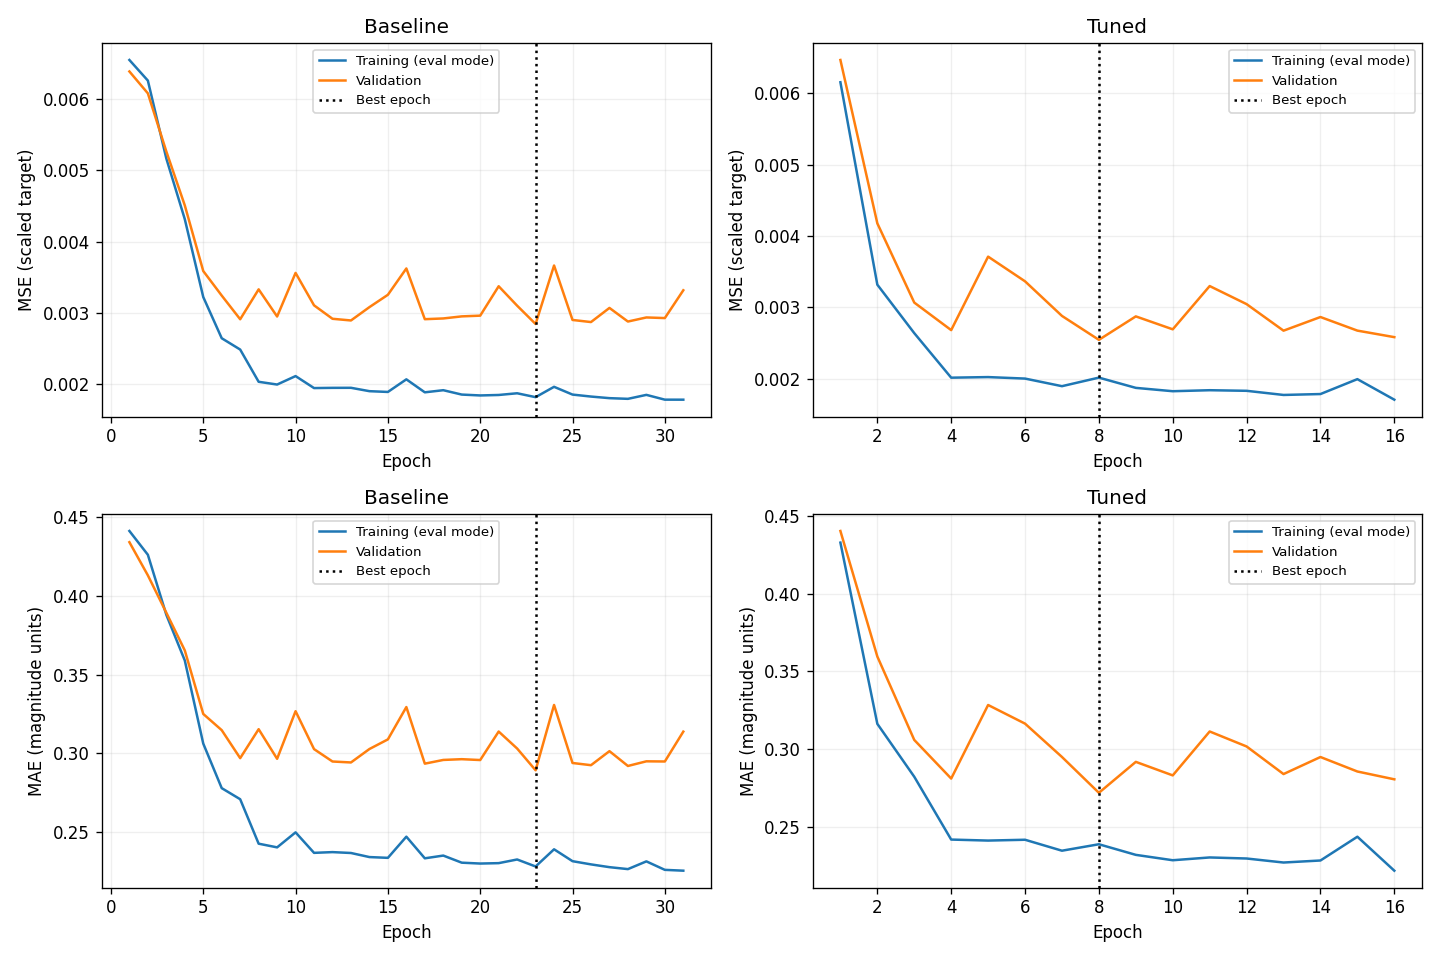

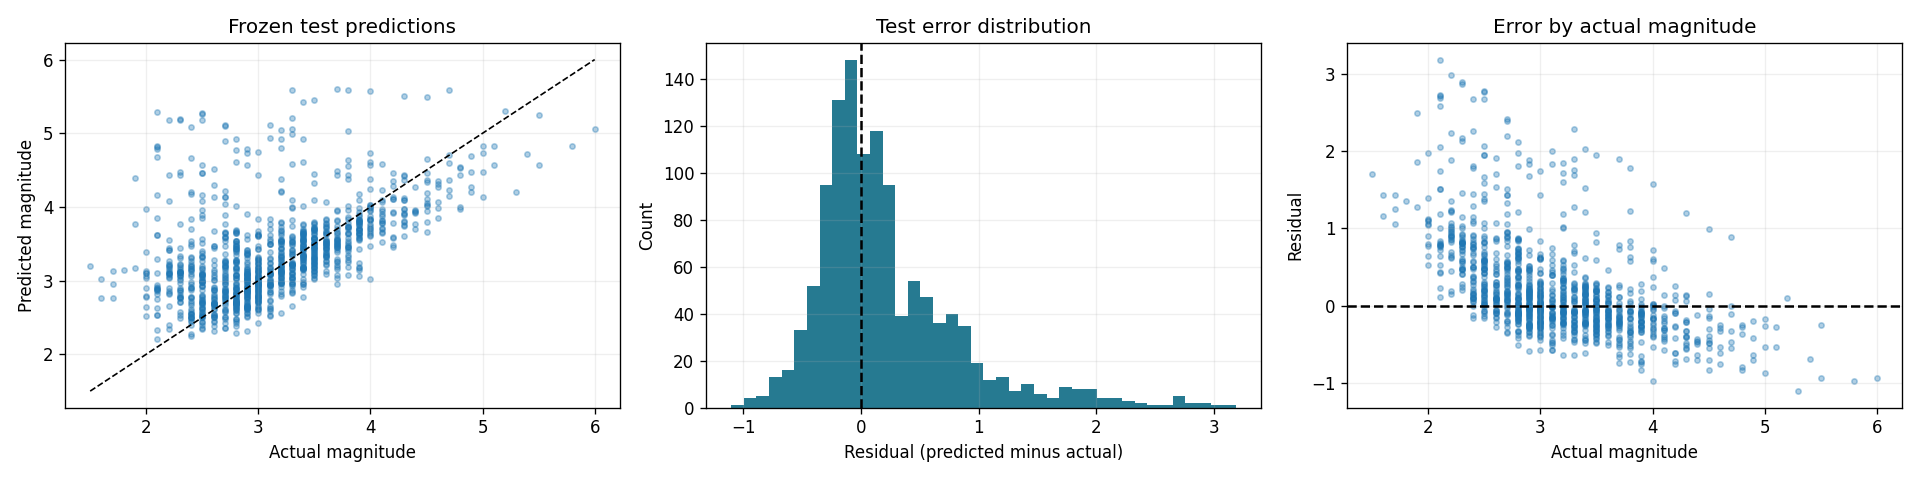

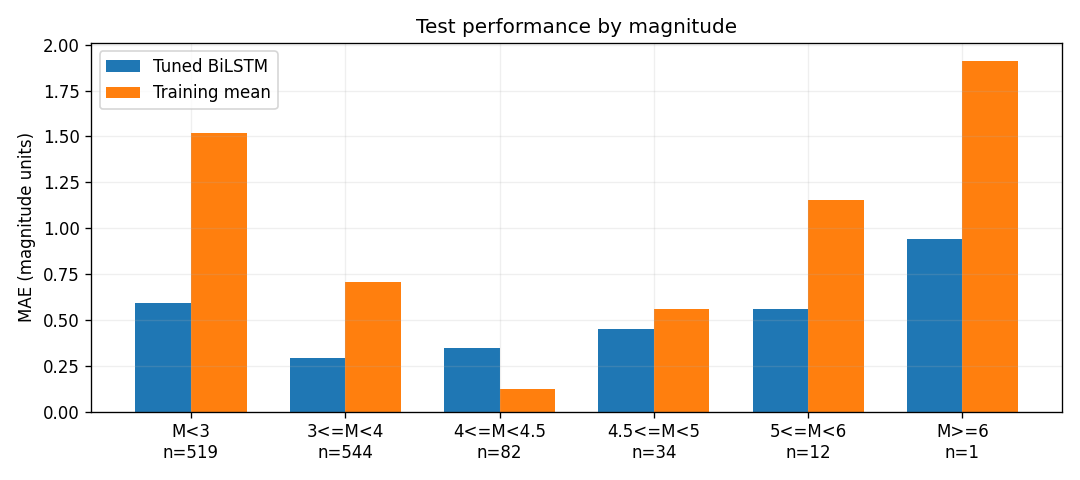

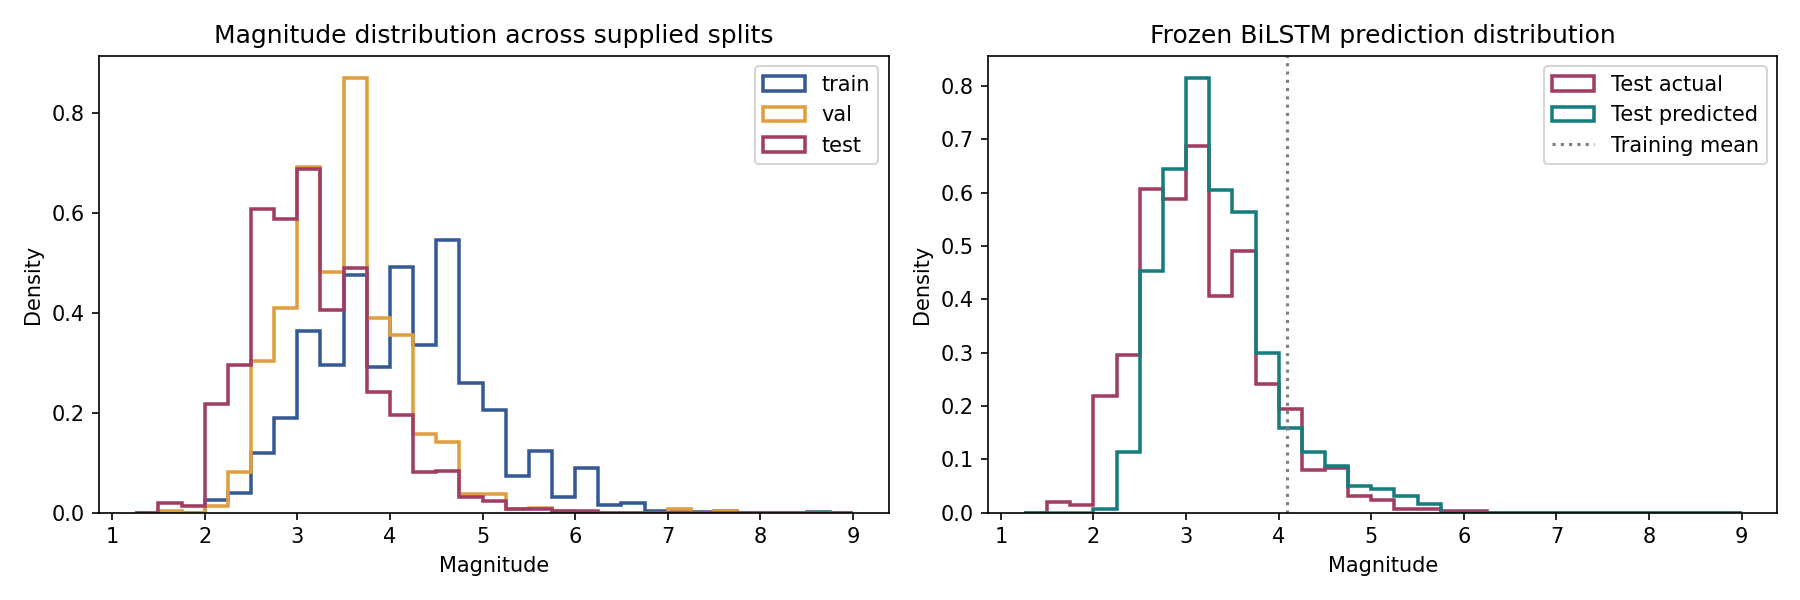

{
  "report": "C:\\Users\\choud\\Desktop\\Minor project\\bilstm\\phase2_bilstm_results\\generalization_audit\\audit_report.md",
  "ridge_alpha": 0.1,
  "ridge_test": {
    "n": 1192,
    "mae": 0.6927158001614331,
    "rmse": 1.2701788081004426,
    "bias": 0.3391358863284659,
    "r2": -2.7694236873334854
  },
  "original_artifacts_unchanged": true
}


In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
bins=np.arange(1.25,9.01,.25)
for s,color in zip(splits,("#345995","#e09f3e","#a13d63")):
    axes[0].hist(y[s],bins=bins,density=True,histtype="step",linewidth=1.7,label=s,color=color)
axes[0].set(title="Magnitude distribution across supplied splits",xlabel="Magnitude",ylabel="Density")
axes[0].legend()
for values,label,color in ((actual,"Test actual","#a13d63"),(predicted,"Test predicted","#167d7f")):
    axes[1].hist(values,bins=bins,density=True,histtype="step",linewidth=1.7,label=label,color=color)
axes[1].axvline(mean_value,color="gray",linestyle=":",label="Training mean")
axes[1].set(title="Frozen BiLSTM prediction distribution",xlabel="Magnitude",ylabel="Density")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT/"magnitude_distributions.png",dpi=150)
plt.close(fig)
# No new copies of existing curves, prediction/error plots or magnitude-range plots.
for name in ("training_validation_curves.png","prediction_error_plots.png","performance_by_magnitude.png"):
    display(Image(filename=str(RES/name)))
display(Image(filename=str(OUT/"magnitude_distributions.png")))

ridge_test=metrics(y["test"],ridge_predictions["test"])
ridge_val=metrics(y["val"],ridge_predictions["val"])
median_test=metrics(y["test"],np.full_like(y["test"],median_value))
mean_test=original_metrics["training_mean_baseline"]
substantial_shift=bool(magnitude_shift["test"]["ks_distance"]>=.2 or
                       abs(magnitude_shift["test"]["standardized_mean_difference"])>=.5)
no_collapse=not prediction_shape["constant_collapse_under_std_ratio_0_25"]
next_experiment=(
    "Test the validation-selected Ridge approach on a fresh, provenance-verified event-disjoint holdout, "
    "with all preprocessing fitted on training data. Freeze choices using training/validation only; "
    "do not reuse the current diagnostic test set to tune the model."
    if ridge_test["mae"]<.9*frozen["mae"] and ridge_val["mae"]<=b["best_validation_mae"] else
    "Test a provenance-verified split/preprocessing protocol with validation representing the intended "
    "evaluation population and a fresh event-disjoint holdout. Keep the BiLSTM configuration fixed "
    "to isolate the effect of split design; fit preprocessing on training data only.")
findings={
    "confirmed":{
        "overfitting":curves,"generalization_gaps":gaps,"magnitude_distributions":magnitude,
        "magnitude_shift":magnitude_shift,"input_summary":input_summary,"input_features":feature_records,
        "target_inverse_checks":scaling,"frozen_test_metrics":frozen,
        "prediction_distribution":prediction_stats,"prediction_shape":prediction_shape,
        "error_by_magnitude":range_rows,"large_magnitude_errors":large_errors,
        "error_tail":outliers,"top_error_samples":top_errors,
        "range_violation_error_association":range_violation_errors,
        "ridge_validation_search":ridge_search,"selected_ridge_alpha":selected_alpha,
        "ridge_fit_seconds":ridge_seconds,"baseline_comparison":baseline_rows},
    "hypotheses":{
        "leading_explanation":"Split distribution mismatch with magnitude-dependent bias and a high-error tail; late overfitting contributes but does not alone establish the source of the larger test gap.",
        "causality":"The role of individual features, preprocessing provenance, event overlap and target timing is unverified.",
        "significance":"Large descriptive effect sizes do not provide a valid independence-aware significance test."},
    "next_experiment":next_experiment,
    "environment":{"numpy":np.__version__,"torch":str(torch.__version__),"sklearn":sklearn.__version__},
    "protocol":baseline_protocol}
write_json(OUT/"audit_measurements.json",findings)

comparison_lines=["| Model | Validation MAE | Test MAE | Test RMSE | Test R² |",
                  "|---|---:|---:|---:|---:|"]
for name in ("Training mean","Training median","Ridge","Tuned BiLSTM"):
    v=baseline_table[(baseline_table.model==name)&(baseline_table.split=="val")].iloc[0]
    t=baseline_table[(baseline_table.model==name)&(baseline_table.split=="test")].iloc[0]
    comparison_lines.append(f"| {name} | {v.mae:.4f} | {t.mae:.4f} | {t.rmse:.4f} | {t.r2:.4f} |")
range_lines=["| Actual magnitude | n | MAE | RMSE | Bias (predicted−actual) | Underpredicted |",
             "|---|---:|---:|---:|---:|---:|"]
for r in range_rows:
    range_lines.append(f"| {r['range']} | {r['n']} | {r['mae']:.4f} | {r['rmse']:.4f} | {r['bias']:+.4f} | {r['underprediction_fraction']:.1%} |")
input_text="; ".join(
    f"{s}: range [{input_summary[s]['minimum']:.4f}, {input_summary[s]['maximum']:.4f}], "
    f"{input_summary[s]['sample_fraction_outside_training_range']:.1%} of windows outside training feature ranges"
    for s in ("val","test"))
ridge_verdict=("Ridge also outperforms the BiLSTM on test MAE and RMSE."
               if ridge_test["mae"]<frozen["mae"] and ridge_test["rmse"]<frozen["rmse"] else
               "Ridge does not beat the BiLSTM on both test MAE and RMSE; see the separate metrics.")
report=f"""# BiLSTM generalization audit

## Diagnosis
**Confirmed:** late overfitting is present, but the selected epoch's train–validation MAE gap is only {gaps['validation_minus_train_mae']:.4f}, versus a test–validation gap of {gaps['test_minus_validation_mae']:.4f} ({gaps['test_to_validation_mae_ratio']:.2f}× validation MAE). Target and input distributions differ across the supplied splits. The target inverse is numerically correct.

**Most likely explanation (hypothesis):** distribution mismatch, magnitude-dependent bias and a high-error tail jointly explain more of the test deterioration than late overfitting alone. This audit cannot assign causality to split design or particular features without feature/event/time provenance.

## Key measurements
- Tuned best-epoch train / validation / test MAE: **{b['best_train_mae']:.4f} / {b['best_validation_mae']:.4f} / {frozen['mae']:.4f}**; RMSE: **{b['best_train_rmse']:.4f} / {b['best_validation_rmse']:.4f} / {frozen['rmse']:.4f}**.
- Magnitude means (train/val/test): **{magnitude['train']['mean']:.4f}/{magnitude['val']['mean']:.4f}/{magnitude['test']['mean']:.4f}**; medians **{magnitude['train']['median']:.2f}/{magnitude['val']['median']:.2f}/{magnitude['test']['median']:.2f}**.
- M≥4.5 proportions: **{magnitude['train']['proportion_M_ge_4_5']:.1%}/{magnitude['val']['proportion_M_ge_4_5']:.1%}/{magnitude['test']['proportion_M_ge_4_5']:.1%}**.
- Train–test target KS distance **{magnitude_shift['test']['ks_distance']:.3f}**, standardized mean difference **{magnitude_shift['test']['standardized_mean_difference']:.3f}**, Wasserstein **{magnitude_shift['test']['wasserstein']:.3f} magnitude units**. Test–validation KS **{magnitude_shift['test_vs_val']['ks_distance']:.3f}**. These quantify descriptive shift, not statistically proven significance: sequence/event independence is unknown.
- Inputs: {input_text}. Features flagged by |sequence-mean standardized difference|≥0.5 or KS≥0.2: validation **{input_summary['val']['flagged_features']}/36**, test **{input_summary['test']['flagged_features']}/36**. Feature identities are unknown; range excursions alone do not prove a scaling defect.
- Predicted/actual test mean: **{prediction_stats['mean']:.4f}/{magnitude['test']['mean']:.4f}**; predicted/actual standard deviation: **{prediction_stats['std']:.4f}/{magnitude['test']['std']:.4f}**, ratio **{prediction_shape['std_ratio_predicted_to_actual']:.3f}**. Prediction-on-actual slope **{prediction_shape['slope_prediction_on_actual']:.3f}**, correlation **{prediction_shape['pearson_correlation']:.3f}**.
- {'No near-constant collapse toward the training mean is supported' if no_collapse else 'Marked prediction-spread collapse is present under the prespecified standard-deviation-ratio screen'}. Conditional shrinkage/bias must be assessed separately from global spread; see the range table.
- Top 1% / 5% of absolute errors account for **{outliers['top_1pct']['squared_error_share']:.1%}/{outliers['top_5pct']['squared_error_share']:.1%}** of squared error. **{outliers['abs_error_gt_1_count']}** samples have |error|>1. Row indices and range-violation associations are in audit_measurements.json; rows are not event identifiers.
- Target inverse maximum discrepancy: **{max(v['max_inverse_error'] for v in scaling.values()):.2g}** across all splits; zero binary-threshold mismatches. This verifies the saved affine mapping, not upstream scaler-fitting provenance.
- Negative test R² means squared error slightly exceeds the test-mean reference; the much weaker training-mean baseline reflects the different train/test target means. The test mean is descriptive, not a deployable fitted baseline.

## Baseline comparison
{chr(10).join(comparison_lines)}

Constants use training data only. Ridge uses 720 flattened sequence features and a training-fitted StandardScaler. Alpha **{selected_alpha:g}** was selected by validation MAE from {ALPHAS} before one diagnostic test evaluation; no BiLSTM training or Optuna search occurred. {ridge_verdict} Baseline results do not authorize test-driven parameter selection.

## Magnitude-dependent errors
{chr(10).join(range_lines)}

For M≥4.5 (n={large_errors['n']}), bias **{large_errors['bias']:+.4f}**, underprediction fraction **{large_errors['underprediction_fraction']:.1%}**, MAE **{large_errors['mae']:.4f}**. Interpret sparse high-magnitude groups cautiously; the largest error in a tiny bin is not a stable population estimate.

## Overfitting and early stopping
First three-epoch divergence from an earlier best: epoch **{b['first_sustained_divergence_epoch']}**; first such divergence after the selected checkpoint: **{b['first_post_selection_divergence_epoch']}**. The first signal can be temporary; validation subsequently reached its global best at epoch **{b['best_epoch']}**.
Training ended at epoch **{b['stop_epoch']}**, exactly **{b['epochs_since_best_at_stop']}** epochs after the best. Training MAE changed **{b['last_minus_best_train_mae']:+.4f}**, validation MAE **{b['last_minus_best_validation_mae']:+.4f}** from best to last. Patience-8 and best-checkpoint restoration worked as intended; they do not protect against distribution shift. The curves support overfitting, but its causal share of the test gap is not identifiable here.

## One prioritized next experiment
{next_experiment}

## Evidence and limits
All analysis is in [the executed notebook](../../phase2_bilstm_generalization_audit.ipynb). Detailed measurements, anonymous feature summaries and high-error rows are in audit_measurements.json; baseline_comparison.csv contains all split metrics. The original model/data/prediction/history/study files are hash-checked before and after the audit.
Figures: [reused curves](../training_validation_curves.png), [reused predictions/errors](../prediction_error_plots.png), [reused range errors](../performance_by_magnitude.png), [new magnitude distributions](magnitude_distributions.png).
No model checkpoint was deserialized. No chronology, event independence, lack of leakage or earthquake forecasting capability is established. No Phase 3 work was performed.
"""
(OUT/"audit_report.md").write_text(report,encoding="utf-8")
after={p.relative_to(ROOT).as_posix():digest(p) for p in protected}
assert before==after, "A protected original artifact changed."
write_json(OUT/"verification.json",{
    "original_artifacts_unchanged":True,"protected_sha256":after,
    "dataset_deserializations":1,"bilstm_checkpoint_loads":0,"bilstm_training_calls":0,
    "optuna_runs":0,"cached_bilstm_metrics_match":True,
    "target_inverse_verified_all_splits":True,"ridge_selection":"validation MAE only",
    "ridge_alpha":selected_alpha,"original_figures_reused":3,"new_figures":1,
    "notebook_final_cell_reached":True})
print(json.dumps({"report":str(OUT/"audit_report.md"),"ridge_alpha":selected_alpha,
                  "ridge_test":ridge_test,"original_artifacts_unchanged":True},indent=2))


### Reviewed interpretation
The strongest observed input association is range violation: 376 test windows outside training feature ranges have MAE **0.6937**, versus **0.3145** for the other 816 (RMSE **0.9928** versus **0.4168**). All ten largest errors belong to the former group. Magnitude or other differences may confound this association; it does not establish that clipping or rescaling would help.
The BiLSTM beats all three diagnostic baselines on test MAE and RMSE. **M<3** is the worst well-populated magnitude range; M>=6 contains only one test sample. The recommended next experiment is the fixed-model split/preprocessing comparison in the report, not more optimization on this test set.